# Grammar Scoring Engine for Spoken English — SHL Hiring Assessment 2026

**Task.** Each audio clip is 45–60 s of a person speaking English. Predict the grammar score (MOS Likert, 1–5, rubric below) that human raters gave it.
Leaderboard metric: RMSE (Pearson also reported).

**Result.** Final submission (v10): **public leaderboard RMSE 0.3465**.
Honest cross-validation on unseen speakers: **RMSE 0.547, Pearson 0.841**. Training RMSE is in [section 7](#7.-Results).

| Score | Rubric (abridged) |
|:-:|---|
| 1 | Struggles with sentence structure; memorised patterns only |
| 2 | Simple structures with consistent basic mistakes; incomplete sentences |
| 3 | Decent grasp of structure *or* grammar, with errors in the other |
| 4 | Strong control; occasional minor errors, mostly self-corrected |
| 5 | High accuracy, complex structures, self-corrects |

### Contents
1. Approach in one picture
2. Data and two findings that shaped the solution
3. Preprocessing
4. Features
5. Speaker leakage and honest validation
6. Models and stacking
7. Results (incl. training RMSE)
8. What did not work, and limitations

## 1. Approach in one picture

```
                      ┌──────────────────────── text branch ─────────────────────────┐
 audio (.wav) ──► Whisper large-v3 ──► verbatim transcript ──► grammar-error rate (CoEdIT corrector)
   16 kHz mono      (speech-to-text)          │                 GPT-2 sentence surprise, fluency stats
   first 45 s                                 ├──────────────► LLM examiner (Qwen) reads rubric → score 1–5
        │                                     └──────────────► text embeddings (bge, mpnet), char n-grams
        │
        ├──────────── audio branch ──────────► WavLM-large / Whisper-encoder layer embeddings (frozen)
        └────────────────────────────────────► Whisper encoder fine-tuned on the scores
                                                          │
         13 + 7 + 1 base models (ridge / LightGBM) ───────┴──► non-negative linear stack ──► score (clipped 1–5)
```

**Why both branches.** The rubric is about grammar, which is visible in *what* is said (text). Raters also hear *how* it is said: hesitations, restarts, rhythm. Those correlate with grammatical control and are only in the audio.

**Where things run.** GPU steps ran as Kaggle scripts (`kernels/` in the repo); their outputs (transcripts, features, embeddings, fine-tuned predictions) were downloaded to `outputs/`. This notebook loads them and does all modelling, evaluation and plotting via `src/pipeline.py`, which also produces the submission file (`python src/predict.py`).

| Kaggle script | What it produces |
|---|---|
| `kernels/transcribe/transcribe.py` | Whisper large-v3 transcripts + word timings |
| `kernels/features/features.py` | grammar-error, language-model and fluency features; text embeddings |
| `kernels/llm_judge/llm_judge.py` | LLM-examiner scores (Qwen2.5-7B, Qwen3-8B) |
| `kernels/audio45/audio_emb45.py` | WavLM-large and Whisper-encoder embeddings of the first 45 s |
| `kernels/finetune_whisper_g/finetune_whisper_g.py` | Whisper encoder fine-tuned with speaker-grouped folds |

In [1]:
import os, sys, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize

if os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")                      # run from the repository root
sys.path.insert(0, "src")
import pipeline as P

# Chart style: one hue per role, recessive axes/grid
BLUE, ORANGE, INK, MUTED, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "figure.dpi": 110,
})

## 2. Data and two findings that shaped the solution

769 labelled training clips and 216 test clips.

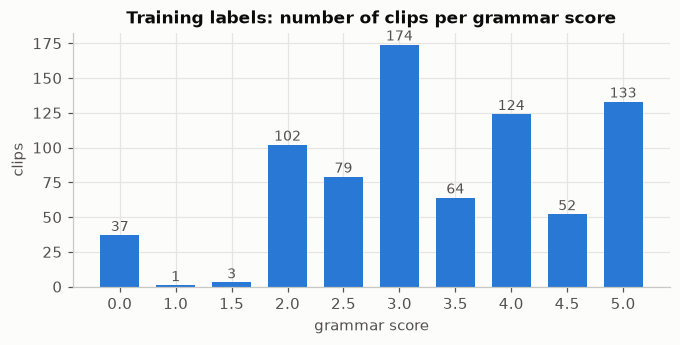

score-0 clips: 37 | their file numbers: 5037 - 5073
score > 0 clips with file number >= 5000: 0
test clips with file number >= 5000: 0


In [2]:
train = pd.read_csv(f"{P.DATA}/train.csv")
counts = train.label.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(counts.index.astype(str), counts.values, color=BLUE, width=0.7)
for x, v in zip(counts.index.astype(str), counts.values):
    ax.text(x, v + 3, str(v), ha="center", fontsize=9, color=MUTED)
ax.set_title("Training labels: number of clips per grammar score")
ax.set_xlabel("grammar score"); ax.set_ylabel("clips")
plt.show()

ids = train.filename.str.extract(r"(\d+)")[0].astype(int)
print("score-0 clips:", (train.label == 0).sum(), "| their file numbers:", ids[train.label == 0].min(), "-", ids[train.label == 0].max())
print("score > 0 clips with file number >= 5000:", ((ids >= 5000) & (train.label > 0)).sum())
test_ids = pd.read_csv(f"{P.DATA}/test.csv").filename.str.extract(r"(\d+)")[0].astype(int)
print("test clips with file number >= 5000:", (test_ids >= 5000).sum())

**Finding 1: the 37 score-0 clips are a separate batch.** The rubric defines scores 1–5 only. All 37 zeros (and nothing else) are files 5037–5073, and the test set has no files from that batch. Their transcripts read like ordinary speech, so these look like invalid or off-protocol recordings, not "grammar 0". Keeping them pulls predictions down for test clips that can never be zeros. **They are dropped from training** (732 clips remain). This alone improved CV RMSE from 1.08 to 0.81 in the first baseline.

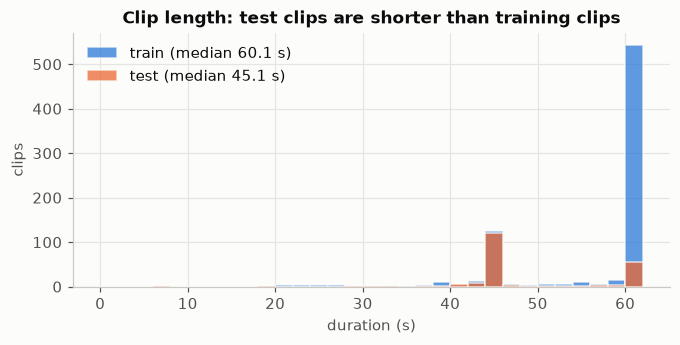

In [3]:
docs = pd.DataFrame(json.load(open(f"{P.OUT}/asr/transcripts.json")))[["split", "duration"]]
fig, ax = plt.subplots(figsize=(7, 3))
bins = np.arange(0, 64, 2)
for split, color in [("train", BLUE), ("test", ORANGE)]:
    d = docs[docs.split == split].duration
    ax.hist(d, bins=bins, color=color, alpha=0.75, label=f"{split} (median {d.median():.1f} s)",
            edgecolor=SURFACE, linewidth=1)
ax.set_title("Clip length: test clips are shorter than training clips")
ax.set_xlabel("duration (s)"); ax.set_ylabel("clips"); ax.legend(frameon=False)
plt.show()

**Finding 2: test clips are shorter** (median 45 s vs 60 s). Features that grow with clip length (word count, number of pauses, …) would shift for every test clip. Two fixes:
* counts are replaced by per-second **rates**;
* audio embeddings are computed on the **first 45 s** of every clip, train and test alike.

## 3. Preprocessing

* **Audio**: decoded with `librosa`, resampled to 16 kHz mono, truncated to the first 45 s for embeddings (60 s for transcription).
* **Transcription**: Whisper large-v3 (`faster-whisper`, beam 5). Whisper normally "cleans up" speech, dropping fillers and silently fixing small grammar errors, which would hide exactly what we score. It is therefore prompted with a deliberately disfluent, ungrammatical example (`"Umm, so, uh, I think that, like, he go to the school and, hmm, we was there."`), which steers it towards verbatim output. Word timings and confidences are kept.
* **Sentences**: transcripts are split on sentence punctuation; run-ons are cut into ≤40-word chunks for the grammar corrector.
* **Labels**: score-0 batch removed (section 2).

## 4. Features

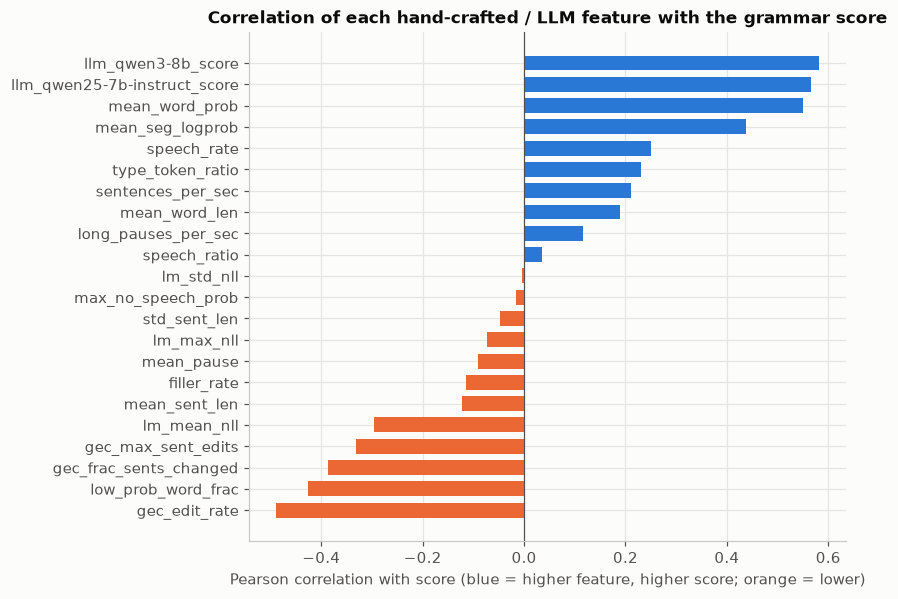

In [4]:
res = P.run(verbose=False)
f, tr, y = res["f"], res["tr"], res["y"]
hand, llm = P.column_groups(f)
corr = f[tr][hand + [c for c in llm if c.endswith("_score")]].corrwith(f.label[tr]).sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(corr.index, corr.values, color=[ORANGE if v < 0 else BLUE for v in corr.values], height=0.7)
ax.axvline(0, color=MUTED, linewidth=0.8)
ax.set_title("Correlation of each hand-crafted / LLM feature with the grammar score")
ax.set_xlabel("Pearson correlation with score (blue = higher feature, higher score; orange = lower)")
plt.show()

| Group | Features | How |
|---|---|---|
| **Grammar errors** | `gec_edit_rate`, `gec_frac_sents_changed`, `gec_max_sent_edits` | Every sentence is corrected by Grammarly's open **CoEdIT-large** ("Fix grammatical errors in this sentence"); we count word-level edits per word spoken. |
| **Language-model surprise** | `lm_mean_nll`, `lm_max_nll`, `lm_std_nll` | GPT-2-medium loss per sentence: ungrammatical sentences are less predictable. |
| **ASR confidence** | `mean_word_prob`, `low_prob_word_frac`, `mean_seg_logprob` | Whisper is more confident on well-formed, clearly articulated English. |
| **Fluency** | speech rate, speech ratio, pauses/s, mean pause, filler rate | From word timings. |
| **Lexical** | type-token ratio, mean word/sentence length | Simple complexity proxies. |
| **LLM examiner** | `llm_*_score`, `llm_*_p1..p5` | Qwen2.5-7B-Instruct and Qwen3-8B (4-bit) read the transcript plus the official rubric. Instead of parsing generated text, we read the next-token probabilities of "1"…"5" and use the expected value, a smooth score. |
| **Text embeddings** | bge-large, all-mpnet-base | Sentence-transformer embeddings of the transcript. |
| **Audio embeddings** | WavLM-large layers 6–24, Whisper-large-v3 encoder layers 8–32 | Hidden states averaged over time, first 45 s. |

The strongest single text signals are Whisper's word confidence (+0.55) and the grammar-corrector edit rate (−0.49): the model has to change more words for lower-scored speakers.

## 5. Speaker leakage and honest validation

The most important methodological finding. Several models looked much better in 5-fold CV than they turned out to be on the leaderboard. The cause: **many training clips have a near-identical voice elsewhere in the training set** (very likely the same speaker answering another prompt), while **test clips never do**. With random folds, a strong model can partly score a clip by recognising the speaker. That works in CV and fails on new speakers.

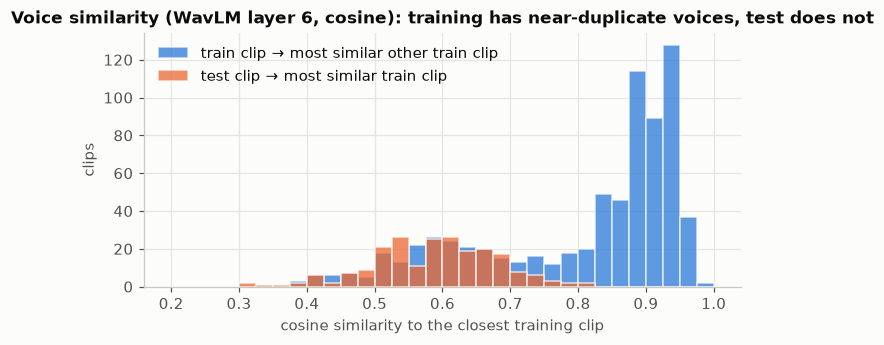

train clips with a near-twin voice (cos > 0.9): 35%; test: 0%
correlation between a clip's score and its voice-twin's score: 0.72
voice groups (agglomerative clustering, cosine distance < 0.25): 427 for 732 clips


In [5]:
V = np.load(f"{P.OUT}/audio2/wavlmL_l6.npy")
V = normalize(V - V[tr].mean(0))
A, B = V[tr], V[(f.split == "test").values]
S = A @ A.T; np.fill_diagonal(S, -1)
nearest_train, nearest_test = S.max(1), (B @ A.T).max(1)
twin_label = y[S.argmax(1)]

fig, ax = plt.subplots(figsize=(7, 3))
bins = np.linspace(0.2, 1, 33)
ax.hist(nearest_train, bins=bins, color=BLUE, alpha=0.75, label="train clip → most similar other train clip", edgecolor=SURFACE)
ax.hist(nearest_test, bins=bins, color=ORANGE, alpha=0.75, label="test clip → most similar train clip", edgecolor=SURFACE)
ax.set_title("Voice similarity (WavLM layer 6, cosine): training has near-duplicate voices, test does not")
ax.set_xlabel("cosine similarity to the closest training clip"); ax.set_ylabel("clips"); ax.legend(frameon=False)
plt.show()

print(f"train clips with a near-twin voice (cos > 0.9): {(nearest_train > 0.9).mean():.0%}; test: {(nearest_test > 0.9).mean():.0%}")
print(f"correlation between a clip's score and its voice-twin's score: {np.corrcoef(y, twin_label)[0, 1]:.2f}")
print(f"voice groups (agglomerative clustering, cosine distance < 0.25): {len(set(res['groups']))} for {len(y)} clips")

**Fix: speaker-grouped cross-validation.** Clips are clustered by voice similarity (agglomerative, average linkage, cosine distance threshold 0.25 on WavLM-large layer-6 embeddings, which mostly carry speaker/acoustic information). `GroupKFold` keeps each cluster inside one fold, so every model is scored on speakers it has never heard, as on the test set. All base models, the stacker and the fine-tuned model use these same folds.

Effect on CV RMSE (same features, random vs grouped folds):

| Model | Random 5-fold | Speaker-grouped | Change |
|---|---|---|---|
| Whisper encoder, fine-tuned | 0.498 | 0.593 | +0.095 |
| WavLM-large L21 + SVR | 0.520 | 0.608 | +0.088 |
| Whisper encoder L8 (mostly voice information) + ridge | 0.696 | 0.774 | +0.078 |
| WavLM-large L21 + ridge | 0.566 | 0.597 | +0.031 |
| Hand + LLM features, LightGBM | 0.690 | 0.699 | +0.009 |
| Character n-grams of transcript | 0.812 | 0.819 | +0.007 |

Audio models (which can hear the voice) lose the most; text models barely change. After the switch, CV and leaderboard **agree**: choices made on grouped CV improved the leaderboard every time (v9, v10), whereas choices made on random CV had twice made it worse (v5, v8).

## 6. Models and stacking

* **Base models** (all evaluated with the grouped folds):
  * ridge / LightGBM on hand + LLM features; ridge on LLM scores alone;
  * ridge on character 2–5-gram TF-IDF of the transcript; ridge on each text embedding;
  * ridge (standardised, α = 1000) on each of 13 audio-embedding layers;
  * **fine-tuned Whisper-large-v3 encoder**: bottom 24 of 32 layers frozen, top 8 + linear head trained (MSE, AdamW, one-cycle LR 2e-5, 6 epochs, random 30 s crops, fp16), predictions averaged over the clip's 30 s windows; 5 grouped folds give honest out-of-fold predictions; test prediction = mean of the 5 fold models.
* **Stack**: ridge with **non-negative** weights (α = 1) on the out-of-fold predictions of all base models. Non-negativity keeps the blend interpretable and stops it from exploiting noise with opposite-sign weights. Final predictions are clipped to [1, 5].

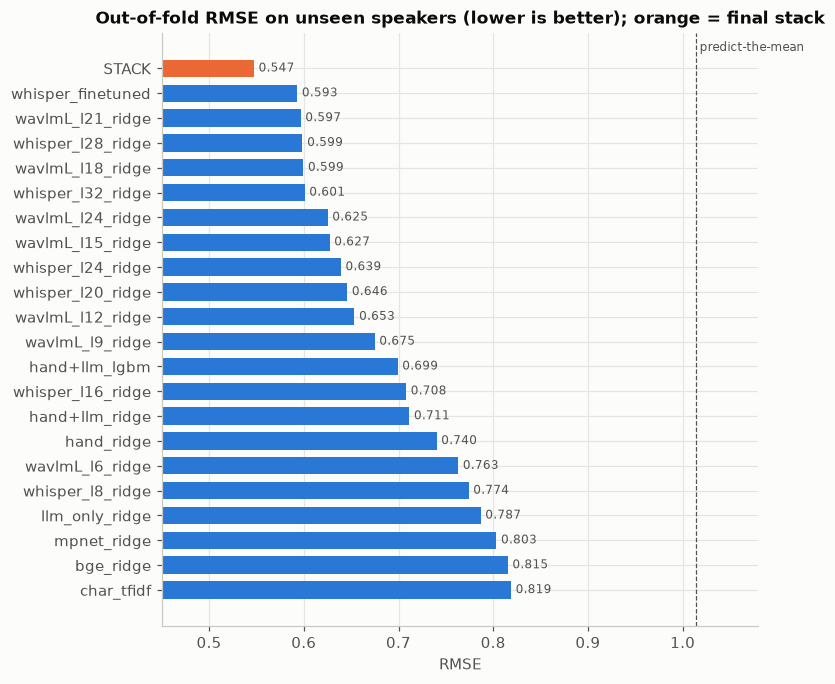

,pearson,rmse
STACK,0.841,0.547
whisper_finetuned,0.812,0.593
wavlmL_l21_ridge,0.807,0.597
whisper_l28_ridge,0.805,0.599
wavlmL_l18_ridge,0.805,0.599
whisper_l32_ridge,0.803,0.601
wavlmL_l24_ridge,0.786,0.625
wavlmL_l15_ridge,0.785,0.627
whisper_l24_ridge,0.775,0.639
whisper_l20_ridge,0.769,0.646


In [6]:
oof = res["oof"]
scores = pd.DataFrame({name: P.metrics(p, y) for name, p in oof.items()}, index=["pearson", "rmse"]).T
scores.loc["STACK"] = P.metrics(res["stack_oof"], y)
scores = scores.sort_values("rmse")

fig, ax = plt.subplots(figsize=(7, 7))
colors = [ORANGE if n == "STACK" else BLUE for n in scores.index]
ax.barh(scores.index[::-1], scores.rmse[::-1], color=colors[::-1], height=0.7)
for i, v in enumerate(scores.rmse[::-1]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8, color=MUTED)
ax.axvline(y.std(), color=MUTED, linewidth=0.8, linestyle="--")
ax.text(y.std(), len(scores) - 0.3, " predict-the-mean", fontsize=8, color=MUTED)
ax.set_xlim(0.45, 1.08)
ax.set_title("Out-of-fold RMSE on unseen speakers (lower is better); orange = final stack")
ax.set_xlabel("RMSE")
plt.show()
scores.round(3)

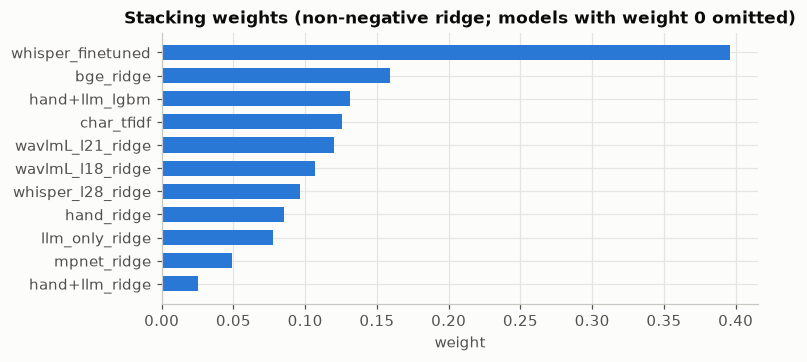

In [7]:
w = pd.Series(res["stacker"].coef_, index=list(oof)).sort_values()
w = w[w > 0]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(w.index, w.values, color=BLUE, height=0.65)
ax.set_title("Stacking weights (non-negative ridge; models with weight 0 omitted)")
ax.set_xlabel("weight")
plt.show()

The stack draws on all three families: the fine-tuned audio model carries the most weight, followed by frozen audio embeddings, text embeddings, and the grammar/LLM features. That is consistent with the rubric being about grammar while raters also hear fluency.

## 7. Results

In [8]:
train_rmse = np.sqrt(np.mean((res["train_pred"] - y) ** 2))
cv_pearson, cv_rmse = P.metrics(res["stack_oof"], y)
print(f"TRAINING RMSE (final model fit on all 732 training clips, predicting those clips): {train_rmse:.3f}")
print(f"Training Pearson:                                                                  {np.corrcoef(res['train_pred'], y)[0, 1]:.3f}")
print(f"Cross-validated RMSE  (speaker-grouped 5-fold, out-of-fold):                       {cv_rmse:.3f}")
print(f"Cross-validated Pearson:                                                           {cv_pearson:.3f}")
print(f"Baseline RMSE (always predict the training mean):                                 {y.std():.3f}")
print("Public leaderboard RMSE (v10):                                                     0.3465")

TRAINING RMSE (final model fit on all 732 training clips, predicting those clips): 0.442
Training Pearson:                                                                  0.900
Cross-validated RMSE  (speaker-grouped 5-fold, out-of-fold):                       0.547
Cross-validated Pearson:                                                           0.841
Baseline RMSE (always predict the training mean):                                 1.014
Public leaderboard RMSE (v10):                                                     0.3465


*Training RMSE* is in-sample, so it is optimistic by construction; the *cross-validated* RMSE is the honest estimate on new speakers. (For the fine-tuned model only out-of-fold predictions exist, so they stand in for its in-sample predictions.) The leaderboard RMSE is lower than CV RMSE, most likely because the (hidden) test labels are less spread out than the training labels; the leaderboard is also computed on only ~60% of the 216 test clips. What matters is that the *ranking* of submissions follows grouped CV.

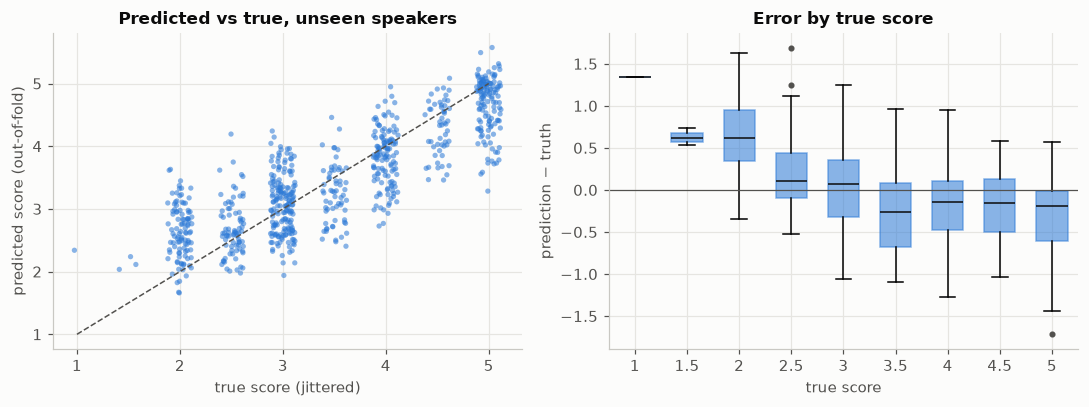

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
ax = axes[0]
jitter = np.random.default_rng(0).uniform(-0.12, 0.12, len(y))
ax.scatter(y + jitter, res["stack_oof"], s=12, color=BLUE, alpha=0.55, edgecolors="none")
ax.plot([1, 5], [1, 5], color=MUTED, linewidth=1, linestyle="--")
ax.set_xlabel("true score (jittered)"); ax.set_ylabel("predicted score (out-of-fold)")
ax.set_title("Predicted vs true, unseen speakers")

ax = axes[1]
levels = sorted(set(y))
err = [res["stack_oof"][y == s] - s for s in levels]
bp = ax.boxplot(err, tick_labels=[f"{s:g}" for s in levels], patch_artist=True, widths=0.6,
                medianprops=dict(color=INK), flierprops=dict(markersize=3, markerfacecolor=MUTED, markeredgecolor=MUTED))
for b in bp["boxes"]:
    b.set(facecolor=BLUE, alpha=0.55, edgecolor=BLUE)
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.set_xlabel("true score"); ax.set_ylabel("prediction − truth")
ax.set_title("Error by true score")
plt.tight_layout(); plt.show()

Like most regressors trained with squared error, the model **regresses towards the mean**: it over-predicts the few 1–2 scores and under-predicts 5s. The middle of the scale (2.5–4) is accurate.

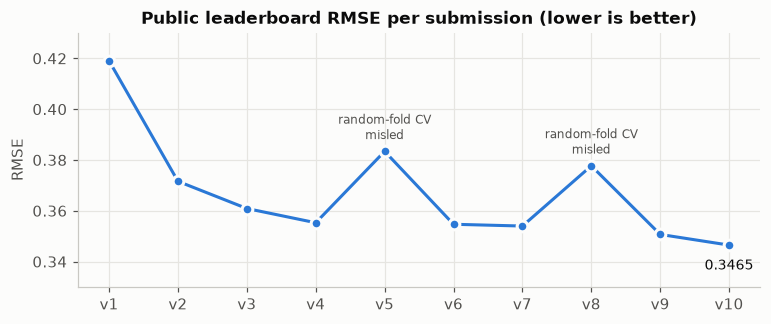

,version,change,public RMSE
0,v1,"Whisper transcript + grammar features, stacked",0.4190
1,v2,+ LLM examiner + WavLM-base audio embeddings,0.3716
2,v3,+ WavLM-large & Whisper-encoder embeddings,0.3609
3,v4,+ fine-tuned WavLM-large (random folds),0.3553
4,v5,+ SVR heads (chosen on random-fold CV),0.3834
5,v6,length-independent hand features,0.3547
6,v7,audio embeddings from first 45 s,0.3540
7,v8,+ fine-tuned Whisper (random folds),0.3777
8,v9,stack weights from speaker-grouped CV,0.3507
9,v10,+ Whisper fine-tuned on grouped folds (final),0.3465


In [10]:
history = pd.DataFrame([
    ("v1", "Whisper transcript + grammar features, stacked", 0.4190),
    ("v2", "+ LLM examiner + WavLM-base audio embeddings", 0.3716),
    ("v3", "+ WavLM-large & Whisper-encoder embeddings", 0.3609),
    ("v4", "+ fine-tuned WavLM-large (random folds)", 0.3553),
    ("v5", "+ SVR heads (chosen on random-fold CV)", 0.3834),
    ("v6", "length-independent hand features", 0.3547),
    ("v7", "audio embeddings from first 45 s", 0.3540),
    ("v8", "+ fine-tuned Whisper (random folds)", 0.3777),
    ("v9", "stack weights from speaker-grouped CV", 0.3507),
    ("v10", "+ Whisper fine-tuned on grouped folds (final)", 0.3465),
], columns=["version", "change", "public RMSE"])

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(history.version, history["public RMSE"], color=BLUE, linewidth=2, marker="o", markersize=7,
        markeredgecolor=SURFACE, markeredgewidth=2)
for v in ["v5", "v8"]:
    r = history[history.version == v].iloc[0]
    ax.annotate("random-fold CV\nmisled", (v, r["public RMSE"]), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=8, color=MUTED)
last = history.iloc[-1]
ax.annotate(f"{last['public RMSE']:.4f}", (last.version, last["public RMSE"]), textcoords="offset points",
            xytext=(0, -16), ha="center", fontsize=9, color=INK)
ax.set_ylim(0.33, 0.43)
ax.set_title("Public leaderboard RMSE per submission (lower is better)")
ax.set_ylabel("RMSE")
plt.show()
history

In [11]:
sub = res["submission"]
sub.to_csv("submission.csv", index=False)
print(sub.shape, "->", "submission.csv")
sub.label.describe().round(3)

(216, 2) -> submission.csv


count    216.000
mean       3.314
std        0.835
min        1.781
25%        2.620
50%        3.237
75%        3.801
max        5.000
Name: label, dtype: float64

## 8. What did not work, and limitations

* **SVR heads on audio embeddings** looked clearly better than ridge on random-fold CV (0.518 vs 0.548) and made the leaderboard worse (v5). Under speaker-grouped CV the advantage vanishes: SVR's locality made it the best at recognising voices.
* **Fine-tuning on random folds** (WavLM v4, Whisper v8) had the same problem. Re-run with grouped folds, the Whisper model's CV dropped from 0.498 to 0.593, and in the stack it then improved the leaderboard (v10).
* **The LLM examiner alone is weak** (Pearson ≈ 0.6): 4-bit 7–8B models compress almost everything into 2–3. It is still useful as one feature among many.

**Limitations and next steps**
* Voice groups are an approximation of speaker identity (no speaker IDs are given); a dedicated speaker-verification model (e.g. ECAPA) would give cleaner groups.
* ASR errors propagate into the text features; non-native accents can be mis-transcribed as grammar errors.
* With more GPU time: fine-tune more audio backbones (and several seeds) on the grouped folds, and fine-tune a text model (e.g. DeBERTa) on transcripts the same way.